***LAB 10***

**K MEANS CLUSTERING**

Load dataset

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
iris = load_iris(as_frame=True)
data = iris.frame
print(data.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


Load dataset from CSV (alternative)

In [3]:
#save the dataset to csv
data.to_csv('iris.csv', index=False)

#load the dataset from csv (for your own file just change the file name/path)
data = pd.read_csv('iris.csv')
print(data.shape)

(150, 5)


Data preprocessing (normalize features)

In [4]:
print(data.isnull().sum().sum())

#clustering is unsupervised so the labels are removed from the features
X = data.drop(columns='target')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

0


Determine the optimal number of clusters using Elbow Method

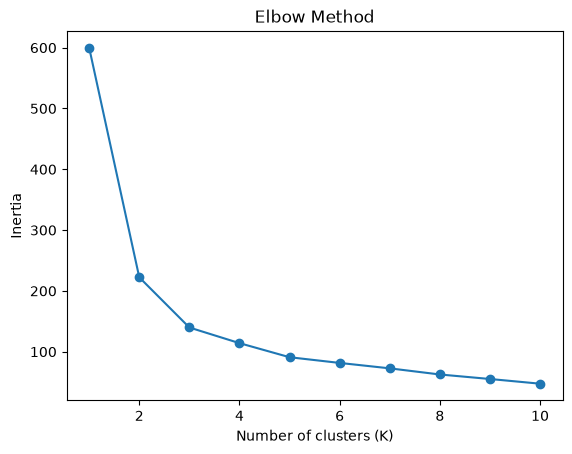

In [5]:
inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

Silhouette score (to confirm the choice of K)

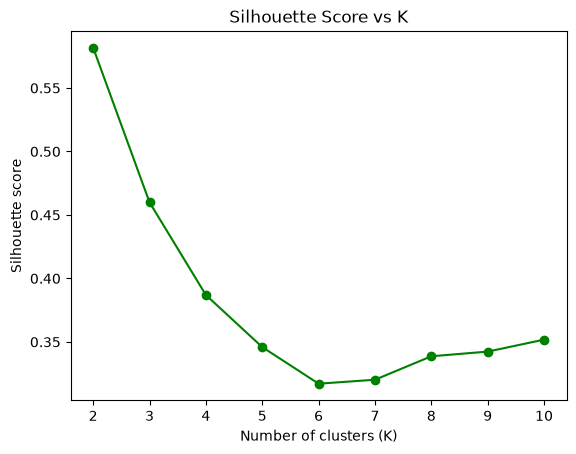

In [6]:
sil = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    sil.append(silhouette_score(X_scaled, km.labels_))

plt.plot(range(2, 11), sil, marker='o', color='green')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette score')
plt.title('Silhouette Score vs K')
plt.show()

The elbow bends around K = 3 and K = 3 is also the true number of species in Iris. (The silhouette score may be a bit higher at K = 2 because setosa is far away from the other two species, but K = 3 still gives well separated clusters.)

Implement K-Means for the selected K

In [7]:
kmeans = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

data['cluster'] = clusters
print(data['cluster'].value_counts())

cluster
0    53
1    50
2    47
Name: count, dtype: int64


Visualize the clusters in 2D (petal length vs petal width)

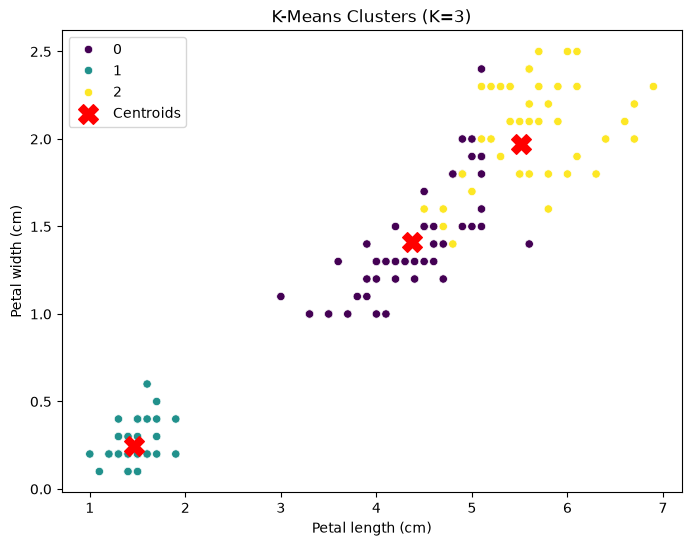

In [8]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)   # back to original units

plt.figure(figsize=(8,6))
sns.scatterplot(x=X['petal length (cm)'], y=X['petal width (cm)'], hue=clusters, palette='viridis')
plt.scatter(centers[:, 2], centers[:, 3], color='red', marker='X', s=200, label='Centroids')
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('K-Means Clusters (K=3)')
plt.legend()
plt.show()

Evaluate the clustering by comparing with the true Iris labels

In [9]:
print(pd.crosstab(data['target'].map(dict(enumerate(iris.target_names))), data['cluster'],
                  rownames=['True species'], colnames=['Cluster']))

print('Adjusted Rand Index =', adjusted_rand_score(data['target'], data['cluster']))
print('Silhouette score    =', silhouette_score(X_scaled, clusters))
print('Inertia             =', kmeans.inertia_)

Cluster        0   1   2
True species            
setosa         0  50   0
versicolor    39   0  11
virginica     14   0  36
Adjusted Rand Index = 0.6201351808870379
Silhouette score    = 0.45994823920518646
Inertia             = 139.82049635974974


Setosa is separated perfectly into its own cluster. Versicolor and virginica overlap a little, so a few flowers of these two species are put in the wrong cluster, which is why the Adjusted Rand Index is good but not 1.

(cluster numbers are just names, so cluster 0 does not have to be the same as class 0.)

*Extra: Mall Customer Segmentation (csv dataset)*

Download Mall_Customers.csv (Kaggle) and keep it in the same folder as this notebook. The cell below runs only if the file is there.

In [10]:
if os.path.exists('Mall_Customers.csv'):
    mall = pd.read_csv('Mall_Customers.csv')
    print(mall.head())

    #use Annual Income and Spending Score
    Xm = mall[['Annual Income (k$)', 'Spending Score (1-100)']]
    Xm_scaled = StandardScaler().fit_transform(Xm)

    #elbow method
    inertia_m = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xm_scaled).inertia_ for k in range(1, 11)]
    plt.plot(range(1, 11), inertia_m, marker='o')
    plt.xlabel('K')
    plt.ylabel('Inertia')
    plt.title('Elbow Method (Mall Customers)')
    plt.show()
else:
    print('Mall_Customers.csv not found, put the file in the notebook folder to run this part')

Mall_Customers.csv not found, put the file in the notebook folder to run this part


In [11]:
if os.path.exists('Mall_Customers.csv'):
    km_m = KMeans(n_clusters=5, n_init=10, random_state=42)
    mall['cluster'] = km_m.fit_predict(Xm_scaled)

    plt.figure(figsize=(8,6))
    sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', hue='cluster', palette='tab10', data=mall)
    centers_m = StandardScaler().fit(Xm).inverse_transform(km_m.cluster_centers_)
    plt.scatter(centers_m[:, 0], centers_m[:, 1], color='black', marker='X', s=200, label='Centroids')
    plt.title('Customer Segments (K=5)')
    plt.legend()
    plt.show()